# End-to-End Hypothesis Testing Case Study

This capstone lesson applies the whole section to **real data**, following the workflow from Lesson 13: question → hypotheses → exploration → assumptions → test → effect size and CI → conclusion and report.

- **Case A (numeric outcome)**: Does vitamin C increase tooth growth, and does the delivery method matter? (`ToothGrowth`)
- **Case B (categorical outcome)**: Was the University of California, Berkeley biased against women in its 1973 graduate admissions? (`UCBAdmissions`) — the classic example of **Simpson's paradox**.

Both datasets ship with R, so everything below is reproducible.

In [1]:
# Notebook setup: wide, readable figures with an opaque white background.
# (Without the hook, base-R plots render with a transparent background and
#  the black axes/labels disappear on dark-themed notebook viewers.)
options(repr.plot.width = 10, repr.plot.height = 6, repr.plot.res = 100)
setHook("before.plot.new", function() par(bg = "white"))

# Case A — Vitamin C and Tooth Growth

## A1. The Question and the Data

In a controlled experiment, 60 guinea pigs received vitamin C at one of three doses (0.5, 1 or 2 mg/day) by one of two delivery methods: orange juice (`OJ`) or ascorbic acid (`VC`). The outcome is the length of the odontoblasts (tooth-growth cells). Each animal received exactly one combination, 10 per cell.

Research questions, fixed **before** looking at the results:
1. Does the dose affect tooth growth?
2. Does the delivery method affect tooth growth — and does its effect depend on the dose?

In [2]:
data(ToothGrowth)
tg <- ToothGrowth
tg$dose <- factor(tg$dose)
str(tg)
table(tg$supp, tg$dose)

'data.frame':	60 obs. of  3 variables:
 $ len : num  4.2 11.5 7.3 5.8 6.4 10 11.2 11.2 5.2 7 ...
 $ supp: Factor w/ 2 levels "OJ","VC": 2 2 2 2 2 2 2 2 2 2 ...
 $ dose: Factor w/ 3 levels "0.5","1","2": 1 1 1 1 1 1 1 1 1 1 ...


    
     0.5  1  2
  OJ  10 10 10
  VC  10 10 10

## A2. Hypotheses and Plan

A 2 (supplement) × 3 (dose) design with independent animals calls for a **two-way ANOVA** (Lesson 17):

- $H_0^{(dose)}$: mean growth is equal for all doses; $H_0^{(supp)}$: equal for OJ and VC; $H_0^{(int)}$: no supplement × dose interaction.
- $\alpha = 0.05$. If an effect is significant → **Tukey** post-hoc comparisons (Lesson 18) and **effect sizes** (partial $\eta^2$).
- Assumptions to check first: normal residuals and equal variances across the six cells (Lesson 15).

## A3. Exploration

 supp dose  mean   sd  n
   OJ  0.5 13.23 4.46 10
   VC  0.5  7.98 2.75 10
   OJ    1 22.70 3.91 10
   VC    1 16.77 2.52 10
   OJ    2 26.06 2.66 10
   VC    2 26.14 4.80 10


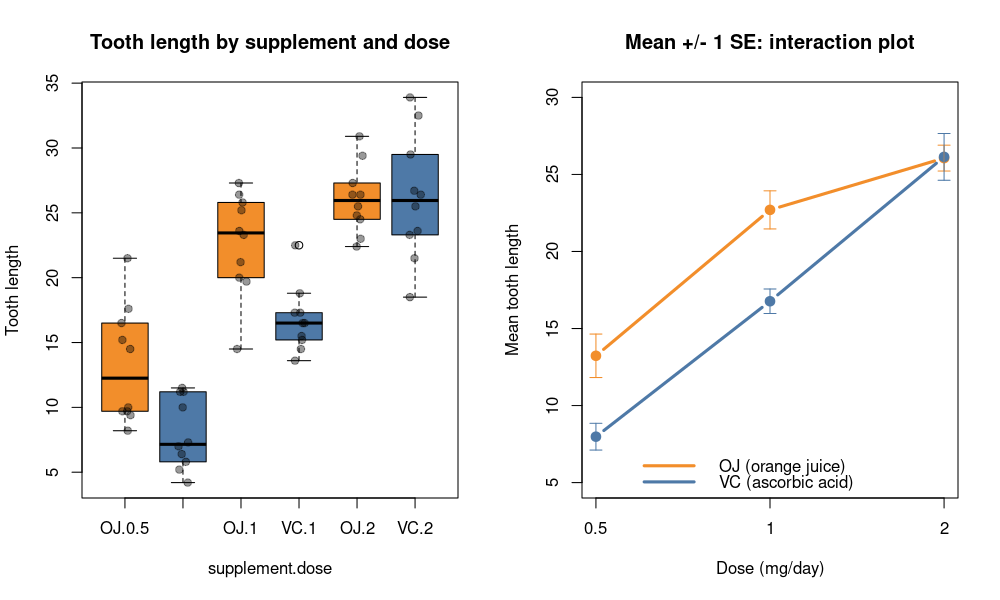

In [3]:
cell_stats <- aggregate(len ~ supp + dose, data = tg, FUN = function(x) c(mean = mean(x), sd = sd(x), n = length(x)))
cell_stats <- do.call(data.frame, cell_stats)
names(cell_stats) <- c("supp", "dose", "mean", "sd", "n")
print(transform(cell_stats, mean = round(mean, 2), sd = round(sd, 2)), row.names = FALSE)

par(mfrow = c(1, 2))
boxplot(len ~ supp + dose, data = tg, col = rep(c("#F28E2B", "#4E79A7"), 3),
        main = "Tooth length by supplement and dose", xlab = "supplement.dose", ylab = "Tooth length")
stripchart(len ~ supp + dose, data = tg, vertical = TRUE, method = "jitter", pch = 19,
           col = adjustcolor("black", 0.4), add = TRUE)

means <- with(tg, tapply(len, list(supp, dose), mean))
ses <- with(tg, tapply(len, list(supp, dose), function(x) sd(x) / sqrt(length(x))))
matplot(1:3, t(means), type = "b", pch = 19, lty = 1, lwd = 3, col = c("#F28E2B", "#4E79A7"), xaxt = "n",
        ylim = c(5, 30), main = "Mean +/- 1 SE: interaction plot", xlab = "Dose (mg/day)", ylab = "Mean tooth length")
axis(1, at = 1:3, labels = levels(tg$dose))
for (i in 1:2) arrows(1:3, means[i, ] - ses[i, ], 1:3, means[i, ] + ses[i, ], angle = 90, code = 3,
                      length = 0.06, col = c("#F28E2B", "#4E79A7")[i])
legend("bottomright", c("OJ (orange juice)", "VC (ascorbic acid)"), col = c("#F28E2B", "#4E79A7"), lwd = 3, bty = "n")

Growth clearly rises with dose. Orange juice looks better at low and medium doses, but the gap disappears at 2 mg. That is a sign of a possible **interaction**.

## A4. Assumption Checks


	Shapiro-Wilk normality test

data:  residuals(model_tg)
W = 0.98499, p-value = 0.6694


,Df,F value,Pr(>F)
,<int>,<dbl>,<dbl>
group,5,1.708578,0.1483606
,54,NA,NA


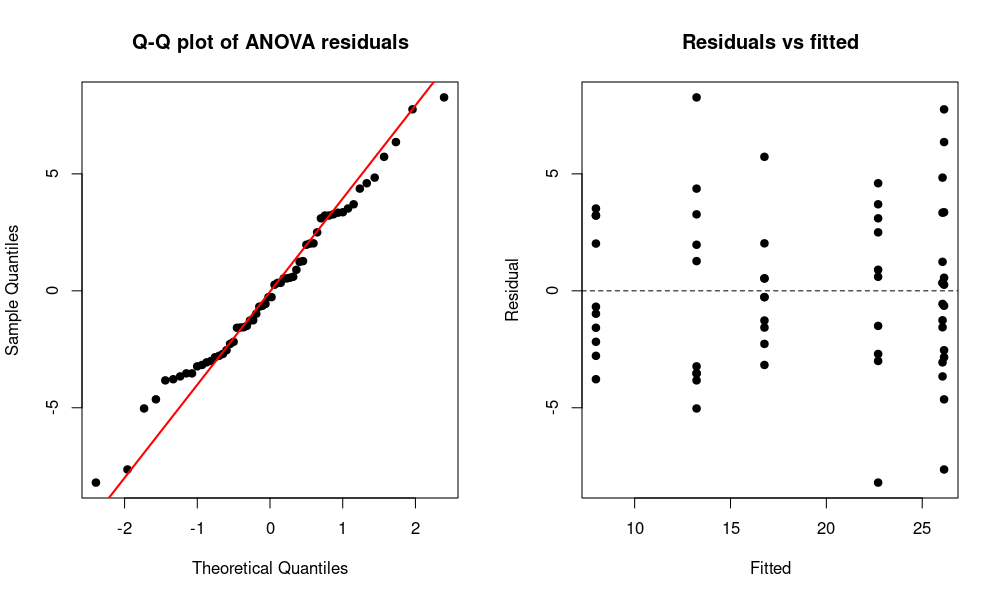

In [4]:
suppressPackageStartupMessages(library(car))
model_tg <- aov(len ~ supp * dose, data = tg)

shapiro.test(residuals(model_tg))
leveneTest(len ~ supp * dose, data = tg)

par(mfrow = c(1, 2))
qqnorm(residuals(model_tg), pch = 19, main = "Q-Q plot of ANOVA residuals"); qqline(residuals(model_tg), col = "red", lwd = 2)
plot(fitted(model_tg), residuals(model_tg), pch = 19, main = "Residuals vs fitted", xlab = "Fitted", ylab = "Residual")
abline(h = 0, lty = 2)

Neither normality (Shapiro–Wilk) nor equal variances (Levene) is rejected, and the plots show no strong pattern. The two-way ANOVA is appropriate.

## A5. The Test

In [5]:
summary(model_tg)

ss <- summary(model_tg)[[1]][["Sum Sq"]]
names(ss) <- trimws(rownames(summary(model_tg)[[1]]))
partial_eta2 <- ss[c("supp", "dose", "supp:dose")] / (ss[c("supp", "dose", "supp:dose")] + ss["Residuals"])
cat("\nPartial eta squared:\n"); print(round(partial_eta2, 3))

            Df Sum Sq Mean Sq F value   Pr(>F)    
supp         1  205.4   205.4  15.572 0.000231 ***
dose         2 2426.4  1213.2  92.000  < 2e-16 ***
supp:dose    2  108.3    54.2   4.107 0.021860 *  
Residuals   54  712.1    13.2                     
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1


Partial eta squared:


     supp      dose supp:dose 
    0.224     0.773     0.132 


All three effects are significant. Dose has a very large effect, and the interaction confirms that the supplement effect **depends on the dose**. So we compare supplements **within each dose** instead of reporting one overall OJ-vs-VC difference.

## A6. Follow-up: Supplement Effect at Each Dose

In [6]:
by_dose <- do.call(rbind, lapply(levels(tg$dose), function(d) {
  sub <- tg[tg$dose == d, ]
  oj <- sub$len[sub$supp == "OJ"]; vc <- sub$len[sub$supp == "VC"]
  tt <- t.test(oj, vc)
  sp <- sqrt((var(oj) + var(vc)) / 2)
  data.frame(dose = d, mean_OJ = mean(oj), mean_VC = mean(vc), diff = mean(oj) - mean(vc),
             ci_low = tt$conf.int[1], ci_high = tt$conf.int[2], p_raw = tt$p.value, cohens_d = (mean(oj) - mean(vc)) / sp)
}))
by_dose$p_holm <- p.adjust(by_dose$p_raw, method = "holm")
print(cbind(by_dose[1], round(by_dose[-1], 3)), row.names = FALSE)

cat("\nTukey HSD for dose (averaged over supplements):\n")
TukeyHSD(model_tg, "dose")

 dose mean_OJ mean_VC  diff ci_low ci_high p_raw cohens_d p_holm
  0.5   13.23    7.98  5.25  1.719   8.781 0.006    1.418  0.013
    1   22.70   16.77  5.93  2.802   9.058 0.001    1.804  0.003
    2   26.06   26.14 -0.08 -3.798   3.638 0.964   -0.021  0.964



Tukey HSD for dose (averaged over supplements):


  Tukey multiple comparisons of means
    95% family-wise confidence level

Fit: aov(formula = len ~ supp * dose, data = tg)

$dose
        diff       lwr       upr   p adj
1-0.5  9.130  6.362488 11.897512 0.0e+00
2-0.5 15.495 12.727488 18.262512 0.0e+00
2-1    6.365  3.597488  9.132512 2.7e-06


## A7. Conclusion and Report

> Tooth growth increased strongly with vitamin C dose, F(2, 54) = 92.0, p < .001, partial $\eta^2$ = 0.77. Delivery method also mattered, F(1, 54) = 15.6, p < .001, but its effect depended on the dose (interaction F(2, 54) = 4.1, p = .02). Orange juice produced longer teeth than ascorbic acid at 0.5 mg (difference 5.3, Holm-adjusted p = .01, d = 1.4) and 1 mg (difference 5.9, Holm-adjusted p = .003, d = 1.8). At 2 mg the two methods did not differ (difference −0.1, 95% CI [−3.8, 3.6]).

**Practical meaning:** if a low dose is used, deliver it as orange juice; at the highest dose, the delivery method doesn't matter.

# Case B — Gender Bias in Graduate Admissions?

## B1. The Question and the Data

In 1973 UC Berkeley's graduate admissions looked suspicious: men appeared to be admitted at a much higher rate than women. The data for the six largest departments are built into R as `UCBAdmissions` (a 2 × 2 × 6 table: Admit × Gender × Dept).

Question: **Is there evidence that women were less likely to be admitted than men?**

In [7]:
data(UCBAdmissions)
overall <- margin.table(UCBAdmissions, c(1, 2))
print(overall)
rate <- prop.table(overall, 2)["Admitted", ]
cat(sprintf("\nAdmission rate: men %.1f%%, women %.1f%%\n", 100 * rate["Male"], 100 * rate["Female"]))

          Gender
Admit      Male Female
  Admitted 1198    557
  Rejected 1493   1278



Admission rate: men 44.5%, women 30.4%


## B2. The Aggregated Analysis

In [8]:
admitted <- overall["Admitted", c("Male", "Female")]
applied  <- colSums(overall)[c("Male", "Female")]
prop.test(admitted, applied, correct = FALSE)

or_overall <- (overall["Admitted", "Male"] / overall["Rejected", "Male"]) /
              (overall["Admitted", "Female"] / overall["Rejected", "Female"])
cat("Odds ratio (men vs women), aggregated:", round(or_overall, 2), "\n")


	2-sample test for equality of proportions without continuity correction

data:  admitted out of applied
X-squared = 92.205, df = 1, p-value < 2.2e-16
alternative hypothesis: two.sided
95 percent confidence interval:
 0.1134470 0.1698439
sample estimates:
   prop 1    prop 2 
0.4451877 0.3035422 


Odds ratio (men vs women), aggregated: 1.84 


Taken at face value: men were admitted at a significantly higher rate (45% vs 30%), and the odds of admission were about 1.8 times higher for men. Case closed? **No.** Admission decisions were made by **departments**, and departments differ a lot in how selective they are.

## B3. Stratify by Department

In [9]:
dept <- do.call(rbind, lapply(dimnames(UCBAdmissions)$Dept, function(d) {
  t <- UCBAdmissions[, , d]
  data.frame(Dept = d,
             applicants_men = sum(t[, "Male"]), applicants_women = sum(t[, "Female"]),
             rate_men = t["Admitted", "Male"] / sum(t[, "Male"]),
             rate_women = t["Admitted", "Female"] / sum(t[, "Female"]),
             dept_admit_rate = sum(t["Admitted", ]) / sum(t))
}))
print(transform(dept, rate_men = round(rate_men, 3), rate_women = round(rate_women, 3),
                dept_admit_rate = round(dept_admit_rate, 3)), row.names = FALSE)

 Dept applicants_men applicants_women rate_men rate_women dept_admit_rate
    A            825              108    0.621      0.824           0.644
    B            560               25    0.630      0.680           0.632
    C            325              593    0.369      0.341           0.351
    D            417              375    0.331      0.349           0.340
    E            191              393    0.277      0.239           0.252
    F            373              341    0.059      0.070           0.064


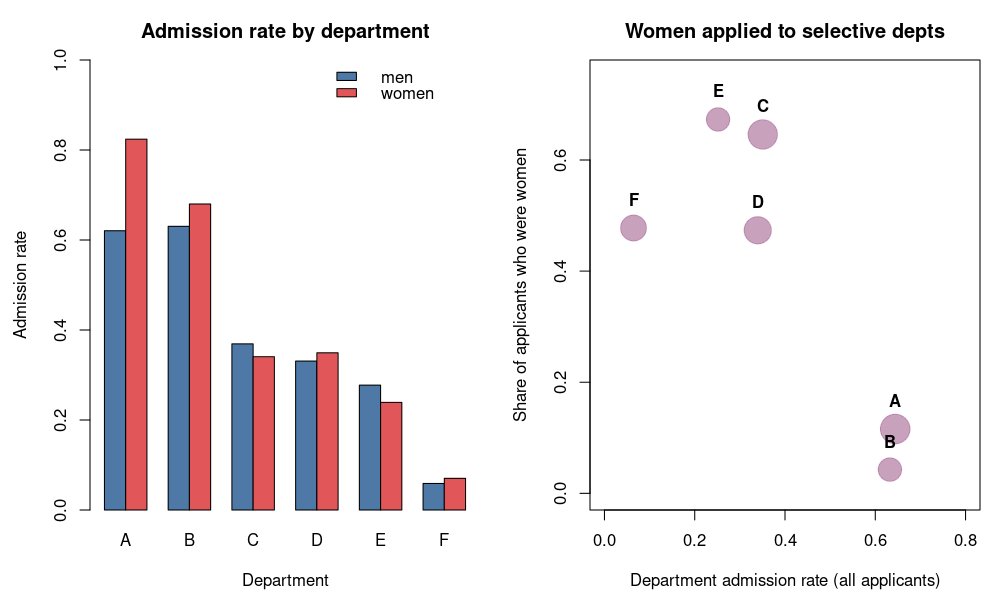

In [10]:
par(mfrow = c(1, 2), mar = c(4.5, 4.5, 3, 1))
bp <- barplot(t(as.matrix(dept[, c("rate_men", "rate_women")])), beside = TRUE, names.arg = dept$Dept,
              col = c("#4E79A7", "#E15759"), ylim = c(0, 1), main = "Admission rate by department",
              ylab = "Admission rate", xlab = "Department")
legend("topright", c("men", "women"), fill = c("#4E79A7", "#E15759"), bty = "n")

share_women <- dept$applicants_women / (dept$applicants_women + dept$applicants_men)
plot(dept$dept_admit_rate, share_women, pch = 19, cex = sqrt((dept$applicants_men + dept$applicants_women) / 60),
     col = adjustcolor("#B07AA1", 0.7), xlim = c(0, 0.8), ylim = c(0, 0.75),
     main = "Women applied to selective depts", xlab = "Department admission rate (all applicants)",
     ylab = "Share of applicants who were women")
text(dept$dept_admit_rate, share_women, dept$Dept, pos = 3, offset = 1.1, font = 2)

Within departments, women's admission rates are **similar to or higher than** men's (department A strongly favours women). The aggregate gap appears because women applied mostly to the **most selective** departments (C–F), while men applied mostly to departments that admitted most applicants (A, B). Department is a **confounder**: it influences both who applies and who gets in.

This reversal is **Simpson's paradox**.

## B4. Testing While Controlling for Department

The **Cochran–Mantel–Haenszel (CMH)** test checks for an association between gender and admission **within** strata (departments) and combines the evidence. It also estimates a common odds ratio across strata.

In [11]:
mantelhaen.test(UCBAdmissions)


	Mantel-Haenszel chi-squared test with continuity correction

data:  UCBAdmissions
Mantel-Haenszel X-squared = 1.4269, df = 1, p-value = 0.2323
alternative hypothesis: true common odds ratio is not equal to 1
95 percent confidence interval:
 0.7719074 1.0603298
sample estimates:
common odds ratio 
        0.9046968 


The common odds ratio is close to 1, with a CI that includes 1. Once department is accounted for, there is **no evidence** that men were favoured.

The same conclusion via **logistic regression** (Lesson 25), which adds department as a predictor:

In [12]:
ucb <- as.data.frame(UCBAdmissions)
ucb$Admit <- ucb$Admit == "Admitted"
ucb$Gender <- relevel(ucb$Gender, ref = "Female")

m_naive <- glm(Admit ~ Gender,        data = ucb, weights = Freq, family = binomial)
m_dept  <- glm(Admit ~ Gender + Dept, data = ucb, weights = Freq, family = binomial)

or_table <- data.frame(
  model = c("Gender only", "Gender + Department"),
  OR_male_vs_female = round(exp(c(coef(m_naive)["GenderMale"], coef(m_dept)["GenderMale"])), 3),
  CI_low  = round(exp(c(confint.default(m_naive)["GenderMale", 1], confint.default(m_dept)["GenderMale", 1])), 3),
  CI_high = round(exp(c(confint.default(m_naive)["GenderMale", 2], confint.default(m_dept)["GenderMale", 2])), 3)
)
print(or_table, row.names = FALSE)

               model OR_male_vs_female CI_low CI_high
         Gender only             1.841  1.624   2.087
 Gender + Department             0.905  0.772   1.060


## B5. Conclusion and Report

> In aggregate, men were admitted more often than women (44.5% vs 30.4%; $\chi^2$(1) = 92.2, p < .001; OR = 1.84). However, admission rates differed strongly between departments, and women applied disproportionately to the more selective ones. After controlling for department, there was no evidence of an advantage for men (Mantel–Haenszel common OR = 0.90, 95% CI [0.77, 1.06], p = .23; logistic regression OR = 0.90 for men vs women). Department A admitted women at a notably higher rate than men.

**Lesson learned:** the aggregate test was *correct arithmetic answering the wrong question*. Statistical tests can't tell you which variables must be held constant; that comes from understanding how the data were generated.

# What This Case Study Practised

| Step | Case A | Case B |
|---|---|---|
| Question and hypotheses fixed in advance | dose, supplement, interaction | admission vs gender |
| Exploration | boxplots, interaction plot | rates, stratified rates |
| Assumptions | Shapiro–Wilk, Levene, residual plots | expected counts, confounding |
| Main test | two-way ANOVA | two-proportion test → CMH test |
| Follow-up | Tukey, per-dose Welch tests with Holm | stratified analysis, logistic regression |
| Effect size and CI | partial $\eta^2$, Cohen's $d$, CI of differences | odds ratios with CIs |
| Conclusion | dose matters; OJ helps at low doses | no bias after controlling for department |

*Insight: In real analyses most of the work happens around the test: framing the question, exploring, checking assumptions, choosing what to control for, and explaining the result. The p-value is one line of the report.*

## Real-World Use Case or Analogy

A hypothesis test is a **courtroom verdict**; the full case study is the **whole investigation**. Detectives (exploration) gather evidence, forensics (assumption checks) verify it's admissible, and the jury (the test) gives a verdict. Then the judge (you) explains what the verdict means and what it doesn't.

The Berkeley case also shows how a correct calculation can still give the wrong answer. Many real controversies, from hospital death rates to school rankings to salary gaps, turn on whether a confounder was controlled. Always ask: *compared within what?*